# Practical Session of Week 3 - Exploratory Data Analysis
This notebook contains the exercises and concepts of **Data Science Practice discipline**.  
Throughout the notebook, we will:

- Explore and datasets using **Pandas** and **NumPy**.  
- Apply **Cleaning and preprocessing Techniques**.
- Perform **Exploratory Data Analysis (EDA)**, including descriptive statistics and vizualizations with plot libraries such as **matplotlib** and **seaborn**.  
- Practice **preprocessing and transformations** to prepare data for analysis.  
- Solve guided examples and exercises to consolidate learning.

The purpose of this notebook is to strengthen your understanding of data exploration, ensuring that you are comfortable dealing with real datasets.

# Part 1: Descriptive Statistics with Python
In this section, we will explore fundamental concepts of quantitative features in rectatuar date.

- Central Tendency: Mean, Mediaan, Mode
- Dispersion: Range, IQR, Variance, STD
- Frequency Tables and Categorical Feature Summaries
- Notion of A Distribution
- Population vs Sample

## 1. Setup & Quick Review
Let's start by importing the necessary libraries and loading a dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dataset: Titanic (small and real-world)
#https://www.kaggle.com/datasets/yasserh/titanic-dataset
df = pd.read_csv("https://raw.githubusercontent.com/zuilpirola/DS/refs/heads/main/Week2/titanic.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Exercise 1
- Explore the dataset with`info()`, `describe()`and check:
  1. How many lines and columns are there?
  2. Which columns are numerical? What are categorical?

In [2]:
df.shape

(891, 12)

In [3]:
#how many lines and columns are in the dataframe
print("Number of lines:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of lines: 891
Number of columns: 12


In [4]:
#Which columns are numerical? What are categorical?
print("Numerical columns:")
print(df.select_dtypes(include=[np.number]).columns)
print("\nCategorical columns:")
print(df.select_dtypes(include=[object]).columns)

Numerical columns:
Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')

Categorical columns:
Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], dtype='object')


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 2. Central trend
Let's calculate average, median and mode for some numerical variables.

In [7]:
print('Média',df["Age"].mean())
print('Mediana',df["Age"].median())
print('Moda',df["Age"].mode())

Média 29.69911764705882
Mediana 28.0
Moda 0    24.0
Name: Age, dtype: float64


In [8]:
from typing import Counter
a = Counter(df['Age'].tolist())
a.most_common(3)

[(24.0, 30), (22.0, 27), (18.0, 26)]

### Exercise 2
1. Calculate the average, median and mode of the variable `Fare`.
2. Compare with the values obtained for `Age`.
3. Note the results and discuss: Is there a significant difference between average and median? What can justify this?

In [9]:
#Calculate the average, median and mode of the variableFare.
df["Fare"].mean(), df["Fare"].median(), df["Fare"].mode()

(np.float64(32.204207968574636),
 14.4542,
 0    8.05
 Name: Fare, dtype: float64)

In [10]:
len(df)

891

In [11]:
#Compare fare with the values obtained for Age in same visualization
df[["Age", "Fare"]].describe()


,Age,Fare
count,714.000000,891.000000
mean,29.699118,32.204208
std,14.526497,49.693429
min,0.420000,0.000000
25%,20.125000,7.910400
50%,28.000000,14.454200
75%,38.000000,31.000000
max,80.000000,512.329200


## 3. Dispersion measurements
Dispersion measures how spread the data.

In [12]:
# Example with Age
age_range = df["Age"].max() - df["Age"].min()
age_iqr = df["Age"].quantile(0.75) - df["Age"].quantile(0.25)
age_var = df["Age"].var()
age_std = df["Age"].std()

age_range, age_iqr, age_var, age_std

(79.58, np.float64(17.875), 211.0191247463081, 14.526497332334044)

### Exercise 3
1. Calculate range, iQR, variance and standard deviation for `Fare`.
2. Compare the results of `Age` and `Fare`.
3. Make a histogram of each variable. Which has the greatest dispersion?

In [13]:
#Calculate range, iQR, variance and standard deviation for Fare
fare_range = df["Fare"].max() - df["Fare"].min()
fare_iqr = df["Fare"].quantile(0.75) - df["Fare"].quantile(0.25)
fare_var = df["Fare"].var()
fare_std = df["Fare"].std()
print("Fare Range:", fare_range)
print("Fare IQR:", fare_iqr)
print("Fare Variance:", fare_var)
print("Fare Standard Deviation:", fare_std)


Fare Range: 512.3292
Fare IQR: 23.0896
Fare Variance: 2469.436845743117
Fare Standard Deviation: 49.693428597180905


In [14]:
#Compare the results of Age and Fare
print("Age Range:", age_range)
print("Age IQR:", age_iqr)
print("Age Variance:", age_var)
print("Age Standard Deviation:", age_std)

#comparison
print("Fare has the greatest dispersion")

Age Range: 79.58
Age IQR: 17.875
Age Variance: 211.0191247463081
Age Standard Deviation: 14.526497332334044
Fare has the greatest dispersion


In [15]:
df['Age'].describe()

,Age
count,714.000000
mean,29.699118
std,14.526497
min,0.420000
25%,20.125000
50%,28.000000
75%,38.000000
max,80.000000


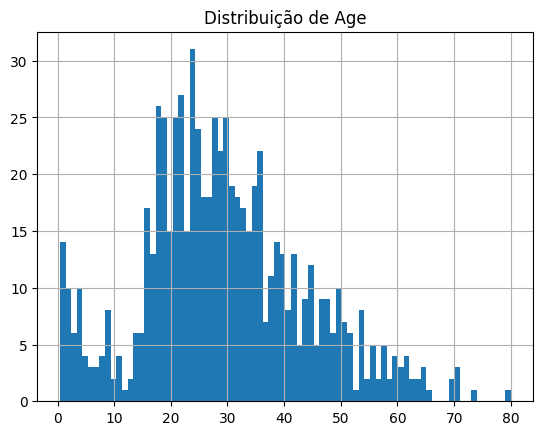

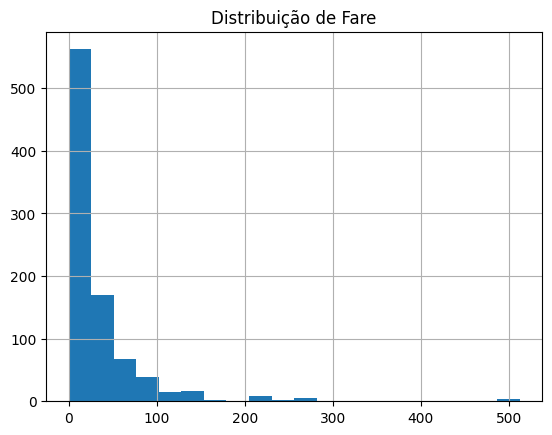

In [16]:
#Make a histogram of each variable. Which has the greatest dispersion
df["Age"].hist(bins=80)
plt.title("Distribuição de Age")
plt.show()

df["Fare"].hist(bins=20)
plt.title("Distribuição de Fare")
plt.show()

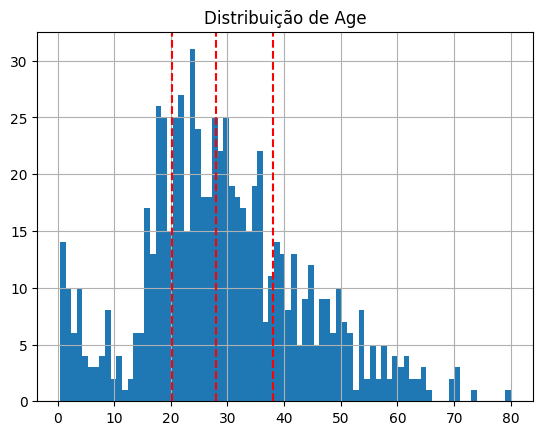

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.12/dist-packages/matplotlib/pyplot.py'>

In [17]:
#Make a histogram of age and print a line in each Quartil
df["Age"].hist(bins=80)
plt.axvline(df["Age"].quantile(0.25), color='r', linestyle='--')
plt.axvline(df["Age"].quantile(0.5), color='r', linestyle='--')
plt.axvline(df["Age"].quantile(0.75), color='r', linestyle='--')
plt.title("Distribuição de Age")
plt.show()
plt


## 4. Distributions and frequencies
Let's explore distributions with histograms and frequencies for categorical variables.

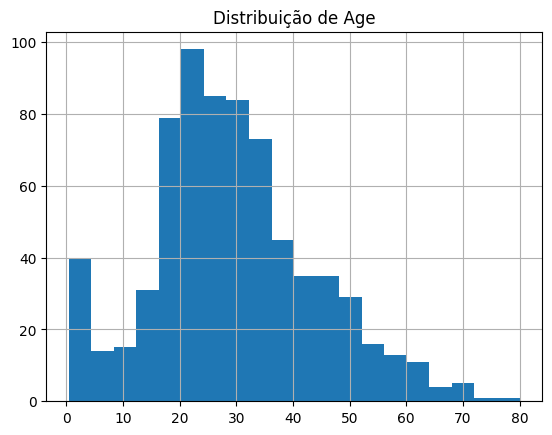

,count
Sex,
male,577
female,314


In [18]:
# Age Distribution
df["Age"].hist(bins=20)
plt.title("Distribuição de Age")
plt.show()

# Sex
df["Sex"].value_counts()

### Exercise 4
1. Make a histogram of `Fare`.
2. Create a frequency table for the variable `Pclass`.
3. Create a Cross Table (CROSSTAB) of `Sex` X `Survived`.
4. Calculate the average `Age` put `Sex`.


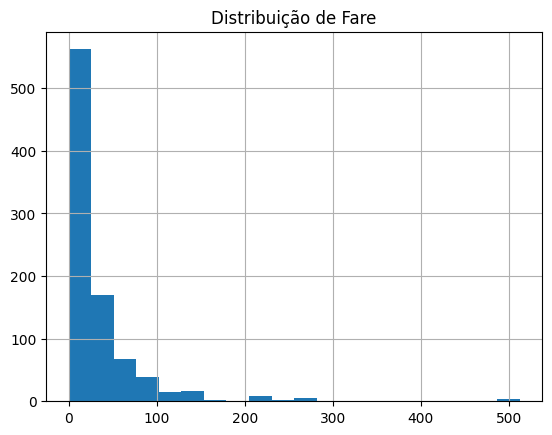

In [ ]:
# Make a histogram of Fare.
df["Fare"].hist(bins=20)
plt.title("Distribuição de Fare")
plt.show()


In [ ]:
#Create a frequency table for the variable Pclass.
df["Pclass"].value_counts()


,count
Pclass,
3,491
1,216
2,184


In [ ]:
#Create a Cross Table (CROSSTAB) of Sex X Survived.
pd.crosstab(df["Sex"], df["Survived"])


Survived,0,1
Sex,,
female,81,233
male,468,109


In [ ]:
#Create a Cross Table (CROSSTAB) of Sex X Survived - Alternative
pd.crosstab(df["Survived"],df["Sex"])

Sex,female,male
Survived,,
0,81,468
1,233,109


In [ ]:
#Calculate the average Age put Sex.
df.groupby("Sex")["Age"].mean()

,Age
Sex,
female,27.915709
male,30.726645


## 5. Population vs Sample
Let's see how statistics can vary between population and sample.

In [51]:
sample_df = df.sample(frac=0.2)

print("Média da população (Age):", df["Age"].mean())
print("Média da amostra (Age):", sample_df["Age"].mean())

print("Mediana da população (Age):", df["Age"].median())
print("Mediana da amostra (Age):", sample_df["Age"].median())

Média da população (Age): 29.69911764705882
Média da amostra (Age): 29.328859060402685
Mediana da população (Age): 28.0
Mediana da amostra (Age): 28.0


### Exercise 5
1. Create a sample of 30% of the data.
2. Compare the average and the standard deviation of`Fare`between the population and this sample.
3. Repeat the process 3 times (with`random_state`different) and note: are the results always the same?

In [48]:
int(len(df) * 0.3) # 30% of the data

267

In [53]:
sample_df = df.sample(frac=0.3) # alternatively df.sample(int(len(df) * 0.3))

print("Média da população (Fare):", df["Fare"].mean())
print("Média da amostra (Fare):", sample_df["Fare"].mean())

print("Mediana da população (Fare):", df["Fare"].median())
print("Mediana da amostra (Fare):", sample_df["Fare"].median())

print(f"Shape of the sample (rows x columns): {sample_df.shape}")

Média da população (Fare): 32.204207968574636
Média da amostra (Fare): 31.622971910112362
Mediana da população (Fare): 14.4542
Mediana da amostra (Fare): 13.7917
Shape of the sample (rows x columns): (267, 12)


## 6. Mini Reflection
Think and discuss in pairs:
- What really means the variable`Age`On this dataset?
- Are there limitations or contexts that we should keep in mind when analyzing it?

In [ ]:
# we can see that the Age refers to the Age of each individual aboard the Titanic, it is measured in years but also includes individuals with less than a year of living (babies) in which case it will show a fraction.
# when we analyzed the Age distribution, we noticed that by taking only a sample from the data does not deviate too much in terms of mean and median.
# when we did the same analysis with the Fare, each sample shows drastically different results for mean. This behaviour is justified by the existence of outliers which influence way too much the mean.
# by checking the median we can confirm how far the mean is from the median

# Part 2: Practical Challenges

In [55]:
import seaborn as sns

## Exercise 1
Average, median and mode`Fare`and`Age`. Then remove the 5% higher (outliers) and recalculate. What has changed?

In [ ]:
# Average, median and mode
for col in ["Fare", "Age"]:
    print(f"{col}: mean={df[col].mean():.2f}, median={df[col].median():.2f}, mode={df[col].mode()[0]}")

# Remove 5% higher values
df_no_outliers = df[(df["Fare"] <= df["Fare"].quantile(0.95)) & (df["Age"] <= df["Age"].quantile(0.95))]

for col in ["Fare", "Age"]:
    print(f"{col} sem outliers: mean={df_no_outliers[col].mean():.2f}, median={df_no_outliers[col].median():.2f}")

Fare: mean=32.20, median=14.45, mode=8.05
Age: mean=29.70, median=28.00, mode=24.0
Fare sem outliers: mean=24.14, median=13.93
Age sem outliers: mean=27.90, median=28.00


## Exercise 2
Compare the average`Age`between passengers who survived (`Survived=1`) and did not survive.

In [ ]:
df.groupby("Survived")["Age"].mean()

Survived
0    30.626179
1    28.343690
Name: Age, dtype: float64

## Exercise 3
Create a function that is called a numerical column and return Mean, Median, Mode.

In [ ]:
def resumo_coluna(col):
    return {
        "mean": df[col].mean(),
        "median": df[col].median(),
        "mode": df[col].mode()[0]
    }

resumo_coluna("Fare")
resumo_coluna("Age")

{'mean': np.float64(29.69911764705882),
 'median': np.float64(28.0),
 'mode': np.float64(24.0)}

## Exercise 4
In what situation is the median better than the average on the Titanic dataset?

In [ ]:
# The median is a better measure of central tendency than the mean when the data contains outliers.
# In the Titanic dataset, the 'Fare' variable has a skewed distribution with some very high values (outliers).
# These outliers heavily influence the mean, pulling it towards the higher values. The median, on the other hand,
# is not affected by outliers and provides a more representative value of the "typical" fare paid by passengers.
# The 'Age' variable, while having some missing values, has a distribution that is less skewed and fewer extreme outliers,
# so the mean and median are closer in value.

## Exercise 5
Calculate range, iQR, variance and standard deviation of`Age`per`Pclass`.


In [ ]:
def dispersao_grupo(col, grupo):
    grouped = df.groupby(grupo)[col]
    resumo = grouped.agg(["min","max","std","var"])
    resumo["range"] = resumo["max"] - resumo["min"]
    resumo["IQR"] = grouped.quantile(0.75) - grouped.quantile(0.25)
    return resumo

dispersao_grupo("Age","Pclass")

,min,max,std,var,range,IQR
Pclass,,,,,,
1,0.92,80.0,14.802856,219.124543,79.08,22.0
2,0.67,70.0,14.001077,196.030152,69.33,13.0
3,0.42,74.0,12.495398,156.134976,73.58,14.0


The output you obtained from the `dispersao_grupo` function shows various dispersion measures for the 'Age' variable, broken down by 'Pclass' (passenger class). Here's a breakdown of what each column represents:

- **min**: The minimum age within each passenger class.
- **max**: The maximum age within each passenger class.
- **std**: The standard deviation of age within each passenger class. This measures the typical deviation of ages from the mean age in that class. A higher standard deviation indicates greater variability in age.
- **var**: The variance of age within each passenger class. This is the square of the standard deviation and also measures the spread of the data.
- **range**: The range of age within each passenger class, calculated as `max - min`. This gives you the total spread of ages in each class.
- **IQR**: The Interquartile Range of age within each passenger class. This is the difference between the 75th percentile (Q3) and the 25th percentile (Q1) of age in each class. It represents the range of the middle 50% of the data and is less sensitive to outliers than the range.

From the results, you can observe how the age distribution and spread vary across the different passenger classes. For example, Pclass 1 has the highest maximum age and a larger range compared to Pclass 2 and 3.

Beyond the range and max age, we can also see that:

*   **Standard Deviation and Variance:** Pclass 1 has the highest standard deviation and variance for Age, indicating that the ages of passengers in the first class are more spread out compared to the other classes. Pclass 3 has the lowest standard deviation and variance, suggesting a more clustered age distribution.
*   **IQR:** The IQR is also highest for Pclass 1, further supporting the idea of greater age variability in the first class. Pclass 2 and 3 have similar IQRs, suggesting a similar spread in the middle 50% of their age distributions.

These observations collectively suggest that passengers in higher classes (Pclass 1) had a wider range of ages and more variability in age compared to those in lower classes (Pclass 2 and 3). This could be due to various factors, such as differences in travel purpose, wealth, or family composition among the different classes.

## Exercise 6
Compare dispersion (STD) of`Fare` and `Sex`.


In [ ]:
df.groupby("Sex")["Fare"].std()

Sex
female    57.997698
male      43.138263
Name: Fare, dtype: float64

## Exercise 7
Identify the numerical variable with the highest coefficient of variation (STD/Mean).

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns
cv = df[num_cols].std()/df[num_cols].mean()
cv.sort_values(ascending=False)

Parch          2.112344
SibSp          2.108464
Fare           1.543073
Survived       1.267701
PassengerId    0.577027
Age            0.489122
Pclass         0.362149
dtype: float64

The output shows the coefficient of variation (CV) for each numerical variable in the dataset, sorted in descending order.

The coefficient of variation is a measure of relative variability. It is calculated as the ratio of the standard deviation to the mean ($\frac{\text{Standard Deviation}}{\text{Mean}}$). A higher CV indicates greater relative variability compared to the mean. It is useful for comparing the dispersion of different datasets, even if their means are drastically different.

Here's what the results indicate for each variable:

- **Parch (2.11):** Has the highest CV, indicating a very high relative variability. This means the number of parents/children aboard varies significantly relative to the average number of parents/children.
- **SibSp (2.11):** Also has a high CV, similar to Parch, suggesting high relative variability in the number of siblings/spouses aboard.
- **Fare (1.54):** Has a high CV, indicating substantial relative variability in the fare paid by passengers. This is consistent with our earlier observation that Fare has outliers that skew the distribution.
- **Survived (1.27):** Represents whether a passenger survived (1) or not (0). The CV here reflects the variability in the survival outcome.
- **PassengerId (0.58):** This is an identifier and the CV is less meaningful in terms of data dispersion.
- **Age (0.49):** Has a relatively lower CV compared to Parch, SibSp, and Fare, suggesting less relative variability in age.
- **Pclass (0.36):** Has the lowest CV, indicating the least relative variability among the numerical features. This makes sense as there are only three passenger classes (1, 2, and 3).

In summary, variables like `Parch`, `SibSp`, and `Fare` show the highest relative variability, suggesting a wider spread of values compared to their means. `Age` and `Pclass` have lower relative variability.

Variables with lower relative variability like 'Age' and 'Pclass' tend to have distributions that are more concentrated around the mean, making the mean a more reliable measure of central tendency.

## Exercise 8
Compare Boxplots of`Fare`between classes`Pclass`.


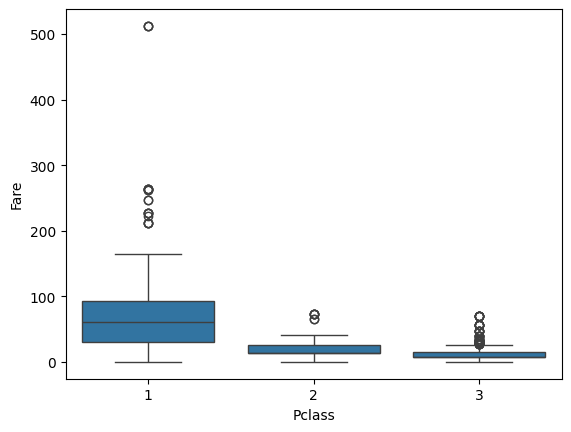

In [ ]:
# alternative using seaborn
sns.boxplot(x="Pclass", y="Fare", data=df)
plt.show()

## Exercise 9
Plot Histograms of`Age` for each `Sex`.

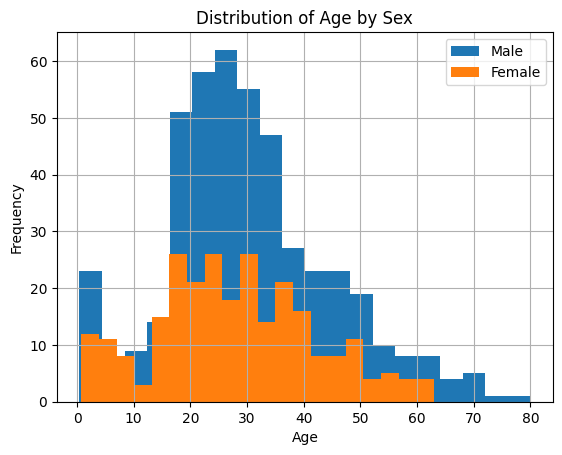

In [60]:
df[df['Sex'] == 'male']['Age'].hist(bins=20, label='Male')
df[df['Sex'] == 'female']['Age'].hist(bins=20, label='Female')
plt.title('Distribution of Age by Sex')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.legend()
plt.show()

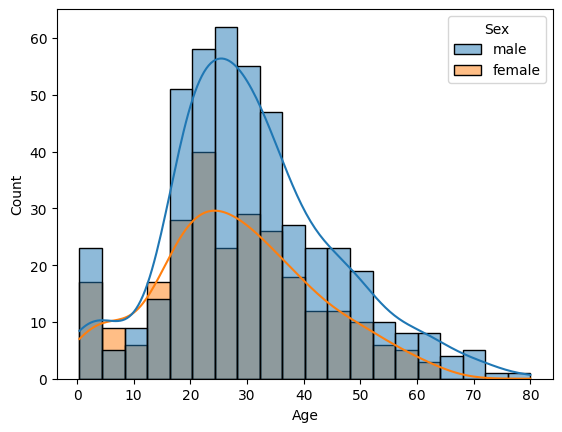

In [57]:
# alternative using seaborn
sns.histplot(data=df, x="Age", hue="Sex", bins=20, kde=True)
plt.show()

## Exercise 10
Cross table`Survived`X`Pclass`with line standardization.

In [ ]:
pd.crosstab(df["Pclass"], df["Survived"], normalize="index")

Survived,0,1
Pclass,,
1,0.370370,0.629630
2,0.527174,0.472826
3,0.757637,0.242363


## Exercise 11
Distribution of`Embarked`percentage

In [ ]:
df["Embarked"].value_counts(normalize=True)

Embarked
S    0.724409
C    0.188976
Q    0.086614
Name: proportion, dtype: float64

## Exercise 12
Average of`Fare`per`Embarked`


In [ ]:
df.groupby("Embarked")["Fare"].mean()

Embarked
C    59.954144
Q    13.276030
S    27.079812
Name: Fare, dtype: float64

## Exercise 13
Proportion of`Sex`within each`Pclass`


In [ ]:
pd.crosstab(df["Pclass"], df["Sex"], normalize="index")

Sex,female,male
Pclass,,
1,0.435185,0.564815
2,0.413043,0.586957
3,0.293279,0.706721


## Exercise 14
5 samples of 20% and average`Age`in each

In [ ]:
for i in range(5):
    sample = df.sample(frac=0.2, random_state=i)
    print(f"Amostra {i+1} mean Age: {sample['Age'].mean():.2f}")

Amostra 1 mean Age: 29.59
Amostra 2 mean Age: 28.04
Amostra 3 mean Age: 29.38
Amostra 4 mean Age: 27.35
Amostra 5 mean Age: 28.46


## Exercise 15
Standard deviation of`Age`for the same samples

In [ ]:
for i in range(5):
    sample = df.sample(frac=0.2, random_state=i)
    print(f"Amostra {i+1} std Age: {sample['Age'].std():.2f}")

Amostra 1 std Age: 14.22
Amostra 2 std Age: 12.96
Amostra 3 std Age: 15.46
Amostra 4 std Age: 13.14
Amostra 5 std Age: 14.29


# Part 3: Reinforcement exercises

This section revisits the descriptive statistics, grouping, frequency tables, visualizations, filters, functions, and sampling techniques used earlier in this notebook. The exercises become gradually more demanding, but they can all be solved by combining methods that have already been introduced.

Continue using the Titanic DataFrame stored in `df`. Read each question carefully and keep intermediate results in clearly named variables.

## R-01 - Central tendency by passenger class

Group the passengers by `Pclass` and calculate the **mean** and **median** of `Fare` for each class. Add a column named `difference` containing the mean minus the median.

Which class shows the largest difference between these two measures? What does this suggest about its fare distribution?

In [ ]:
fare_by_class = df.groupby("Pclass")["Fare"].agg(["mean", "median"])
fare_by_class["difference"] = fare_by_class["mean"] - fare_by_class["median"]
fare_by_class

# First class has the largest difference. Its higher fares are more strongly
# influenced by large values, so the distribution is right-skewed.

## R-02 - Age dispersion by survival outcome

For each value of `Survived`, calculate the minimum, maximum, range, IQR, variance, and standard deviation of `Age`.

Compare the two groups. Do they have similar age dispersion?

In [ ]:
age_groups = df.groupby("Survived")["Age"]

age_dispersion = age_groups.agg(["min", "max", "var", "std"])
age_dispersion["range"] = age_dispersion["max"] - age_dispersion["min"]
age_dispersion["IQR"] = age_groups.quantile(0.75) - age_groups.quantile(0.25)
age_dispersion

# The standard deviations and IQRs are relatively close, although the ranges
# differ because the groups have different extreme ages.

## R-03 - Outlier impact within third class

Create a DataFrame containing only third-class passengers. For this group:

1. Calculate the mean and median `Fare`.
2. Find the 95th percentile of `Fare`.
3. Remove fares above that threshold and recalculate the mean and median.
4. Explain which measure changed more and why.

In [ ]:
third_class = df[df["Pclass"] == 3]
fare_limit = third_class["Fare"].quantile(0.95)
third_class_without_high_fares = third_class[third_class["Fare"] <= fare_limit]

print("Original mean:", third_class["Fare"].mean())
print("Original median:", third_class["Fare"].median())
print("95th percentile:", fare_limit)
print("Mean without highest 5%:", third_class_without_high_fares["Fare"].mean())
print("Median without highest 5%:", third_class_without_high_fares["Fare"].median())

# The mean changes more because it is more sensitive to unusually high fares.
# The median depends on position and is therefore more resistant to outliers.

## R-04 - Survival proportions by sex and class

Create a normalized cross table showing the survival proportions for every combination of `Sex` and `Pclass`.

Each row must sum to 1. Compare the proportion in column `1` (survived) across the groups.

In [ ]:
survival_by_sex_class = pd.crosstab(
    [df["Sex"], df["Pclass"]],
    df["Survived"],
    normalize="index",
)
survival_by_sex_class

# Female passengers have higher survival proportions in every class. Among
# the displayed groups, first-class women have the highest proportion.

## R-05 - Relative variability of fares

For each passenger class, calculate the mean and standard deviation of `Fare`. Then calculate the coefficient of variation:

$$CV = \frac{\text{standard deviation}}{\text{mean}}$$

Sort the result from the highest to the lowest coefficient of variation. Which class has the greatest relative variability?

In [ ]:
fare_variability = df.groupby("Pclass")["Fare"].agg(["mean", "std"])
fare_variability["CV"] = fare_variability["std"] / fare_variability["mean"]
fare_variability.sort_values("CV", ascending=False)

# First class has the greatest relative fare variability in this dataset.

## R-06 - A reusable descriptive summary

Write a function named `descriptive_summary(data, column)` that returns a dictionary containing:

- count;
- mean;
- median;
- mode;
- range;
- IQR;
- variance;
- standard deviation.

Test it with `Age`, `Fare`, and `Age` for passengers who survived.

In [ ]:
def descriptive_summary(data, column):
    values = data[column]
    return {
        "count": values.count(),
        "mean": values.mean(),
        "median": values.median(),
        "mode": values.mode()[0],
        "range": values.max() - values.min(),
        "IQR": values.quantile(0.75) - values.quantile(0.25),
        "variance": values.var(),
        "standard_deviation": values.std(),
    }

print("Age:", descriptive_summary(df, "Age"))
print("Fare:", descriptive_summary(df, "Fare"))
print("Age of survivors:", descriptive_summary(df[df["Survived"] == 1], "Age"))

## R-07 - Two views of age and survival

Create both visualizations below:

1. A boxplot comparing `Age` for passengers who survived and did not survive.
2. Overlapping histograms of `Age` for the same two groups, including a legend.

Use the plots together to comment on differences in center, dispersion, and possible outliers.

In [ ]:
sns.boxplot(x="Survived", y="Age", data=df)
plt.title("Age by survival outcome")
plt.show()

df[df["Survived"] == 0]["Age"].hist(bins=20, alpha=0.6, label="Did not survive")
df[df["Survived"] == 1]["Age"].hist(bins=20, alpha=0.6, label="Survived")
plt.title("Age distribution by survival outcome")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.legend()
plt.show()

# The distributions overlap considerably. The plots reveal differences that
# a single mean cannot show, including spread, concentration, and extremes.

## R-08 - Variability between samples

Take five samples containing 20% of the dataset, using `random_state` values from 0 to 4. Store the mean `Fare` from every sample in a list.

Print the five sample means, the population mean, and the range of the sample means (`maximum - minimum`). What does the range tell you?

In [ ]:
sample_means = []

for state in range(5):
    sample = df.sample(frac=0.2, random_state=state)
    sample_means.append(sample["Fare"].mean())

print("Sample means:", sample_means)
print("Population mean:", df["Fare"].mean())
print("Range of sample means:", max(sample_means) - min(sample_means))

# The range shows sampling variability: different random samples from the same
# population do not produce exactly the same mean.

## R-09 - Difficult: combined group summary

Group the data by both `Pclass` and `Sex`. Build a DataFrame named `group_summary` containing:

- number of passengers;
- mean age;
- median fare;
- fare standard deviation;
- survival proportion.

Remember that the mean of a column encoded with `0` and `1` is the proportion of records equal to `1`.

In [ ]:
grouped = df.groupby(["Pclass", "Sex"])

group_summary = pd.DataFrame({
    "passengers": grouped["PassengerId"].count(),
    "mean_age": grouped["Age"].mean(),
    "median_fare": grouped["Fare"].median(),
    "fare_std": grouped["Fare"].std(),
    "survival_proportion": grouped["Survived"].mean(),
})

group_summary

## R-10 - Difficult: interpret the combined summary

Sort `group_summary` from R-09 by `survival_proportion`, from highest to lowest. Then answer:

1. Which group has the highest survival proportion?
2. Which group has the lowest survival proportion?
3. Why should these descriptive results not automatically be interpreted as proof that class or sex *caused* survival?

In [ ]:
group_summary.sort_values("survival_proportion", ascending=False)

# Highest survival proportion: first-class female passengers.
# Lowest survival proportion: third-class male passengers in this dataset.
# These are observational data. The groups differ in several related factors,
# and descriptive statistics show association rather than proving causation.